In [1]:
import torch
import numpy
import seaborn as sns
import numpy as np
import pandas as pd
import math
from matplotlib import pyplot as plt
import scipy

In [2]:
rollout = torch.load("results/baseline_rollout_train.pt", weights_only=False)
rollout

TensorDict(
    fields={
        agents: TensorDict(
            fields={
                angular_velocity_y: Tensor(shape=torch.Size([51200, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                stacked_lidar: Tensor(shape=torch.Size([51200, 50, 101]), device=cpu, dtype=torch.float32, is_shared=False),
                steering_angle: Tensor(shape=torch.Size([51200, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                throttle: Tensor(shape=torch.Size([51200, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                track_curvature_0_50: Tensor(shape=torch.Size([51200, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                track_curvature_1_00: Tensor(shape=torch.Size([51200, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                track_curvature_1_50: Tensor(shape=torch.Size([51200, 1]), device=cpu, dtype=torch.float32, is_shared=False),
                track_curvature_2_00: Tensor(shape=torch.Size([51

In [3]:
keys = [key for key in rollout['agents'].keys() if key not in ['lidar', 'stacked_lidar', 'throttle', 'steering_angle']]
keys

['velocity_forward',
 'velocity_lateral',
 'track_curvature_0_50',
 'track_curvature_1_00',
 'track_curvature_1_50',
 'track_curvature_2_00',
 'track_curvature_2_50',
 'track_curvature_3_00',
 'track_curvature_3_50',
 'track_curvature_4_00',
 'track_curvature_4_50',
 'track_curvature_5_00',
 'track_curvature_5_50',
 'track_curvature_6_00',
 'track_curvature_6_50',
 'track_curvature_7_00',
 'track_curvature_7_50',
 'track_curvature_8_00',
 'wheel_slip_forward_front_left',
 'wheel_slip_lateral_front_left',
 'wheel_slip_forward_back_left',
 'wheel_slip_lateral_back_left',
 'wheel_slip_forward_front_right',
 'wheel_slip_lateral_front_right',
 'wheel_slip_forward_back_right',
 'wheel_slip_lateral_back_right',
 'angular_velocity_y']

In [4]:
rollout_df = pd.DataFrame(dict(map(lambda kv: (kv[0], np.sort(kv[1].reshape(-1).numpy())), rollout["agents"].select(*keys).to_dict().items())))
rollout_df = (rollout_df - rollout_df.mean()) / rollout_df.std()

In [ ]:
pd.DataFrame({
    "metric": rollout_df.columns,
    "gt_3_sigma": (rollout_df.abs() > 3).mean(),
    "ratio_vs_normal_dist": (rollout_df.abs() > 3).mean() / (1 - scipy.stats.norm.cdf(3))
}).reset_index().rename(columns={"index": "metric"}).to_csv("results/baseline_rollout_heavy_tails.csv", index=False)

,metric,metric,gt_3_sigma,ratio_vs_normal_dist
0,velocity_forward,velocity_forward,0.062598,46.372137
1,velocity_lateral,velocity_lateral,0.000352,0.260436
2,track_curvature_0_50,track_curvature_0_50,0.016738,12.399663
3,track_curvature_1_00,track_curvature_1_00,0.016523,12.240508
4,track_curvature_1_50,track_curvature_1_50,0.012715,9.419114
5,track_curvature_2_00,track_curvature_2_00,0.015391,11.401324
6,track_curvature_2_50,track_curvature_2_50,0.014121,10.460860
7,track_curvature_3_00,track_curvature_3_00,0.015332,11.357918
8,track_curvature_3_50,track_curvature_3_50,0.015293,11.328981
9,track_curvature_4_00,track_curvature_4_00,0.015488,11.473668


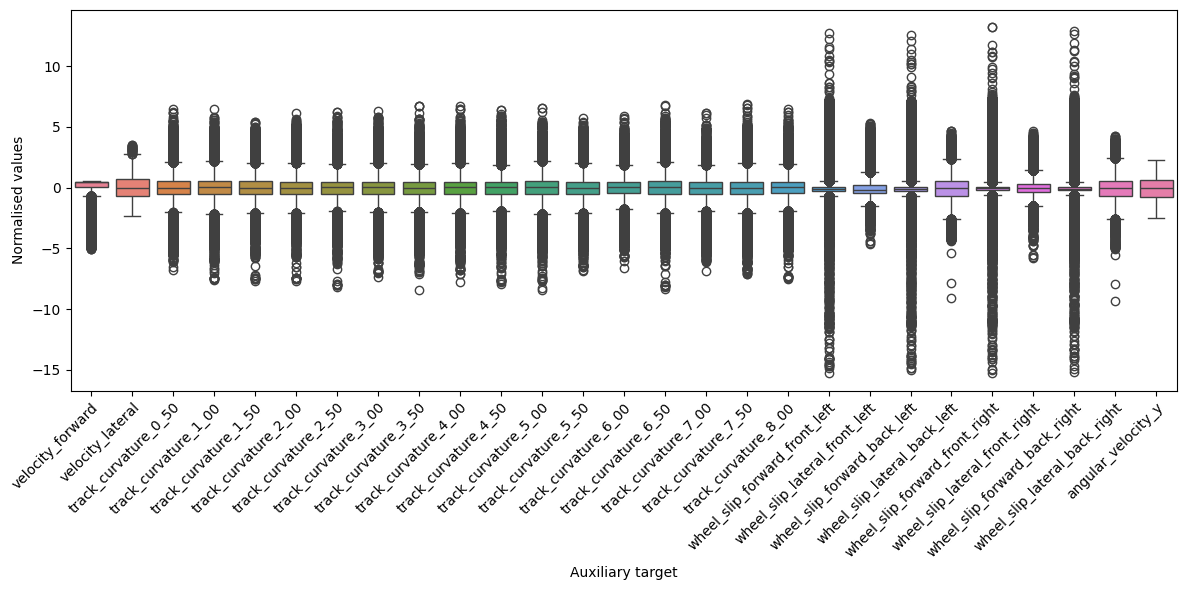

In [10]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=rollout_df).set(ylabel="Normalised values", xlabel="Auxiliary target")
plt.xticks(rotation=45, ha="right", rotation_mode="anchor")
plt.tight_layout()
plt.savefig("results/figures/baseline_rollout_train_boxplot.pdf")

In [29]:
(rollout_df.abs() < 1).mean().to_frame().reset_index().rename(columns={"index": "target", 0: "prop"}).to_csv("results/prop_data_within_1_sd.csv", index=False)

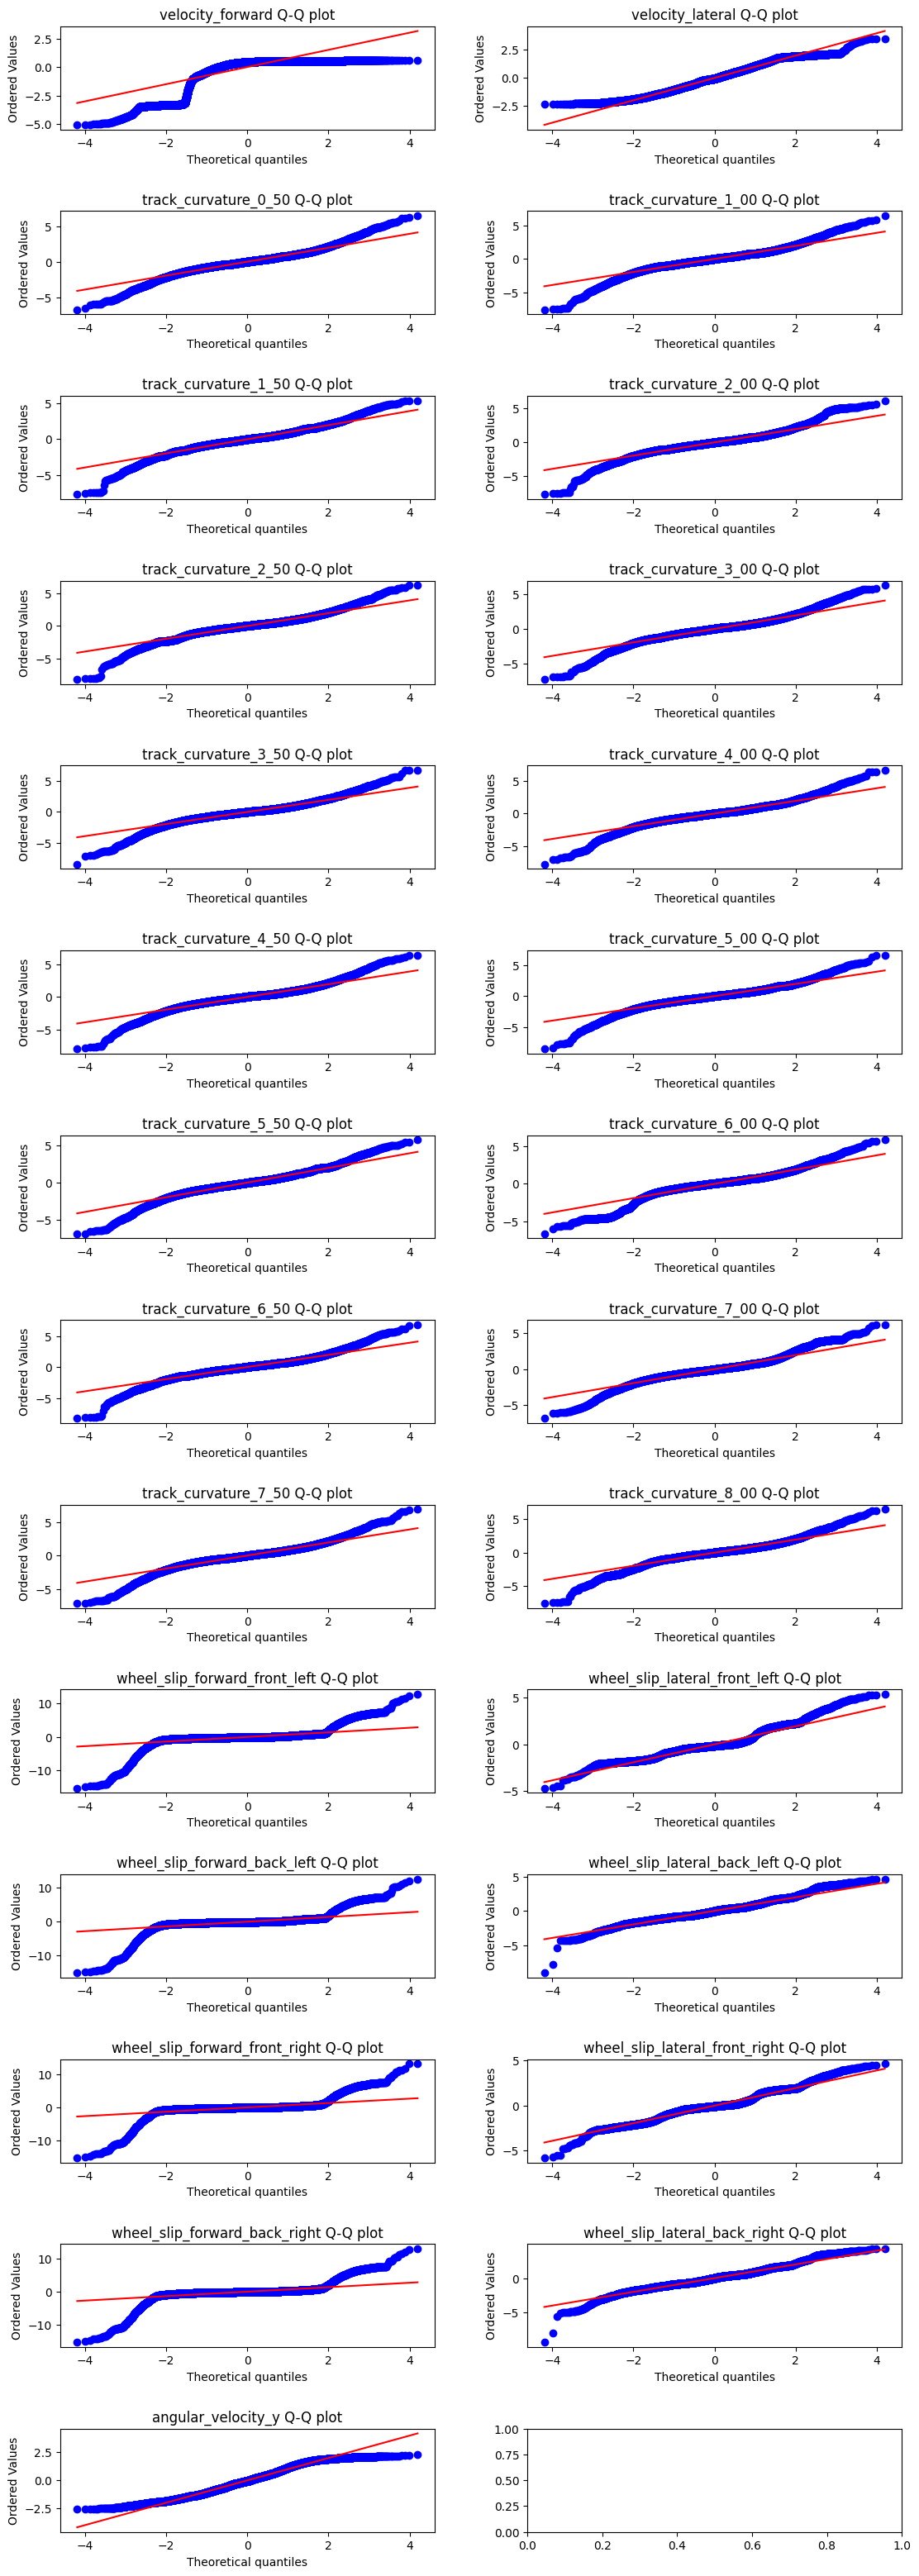

In [ ]:
fig, axs = plt.subplots(math.ceil(len(keys) / 3), 3, figsize=(12, 32))
fig.tight_layout(pad=5.0)
for key in keys:
    scipy.stats.probplot(rollout_df[key], dist="norm", plot=axs.flatten()[keys.index(key)])
    axs.flatten()[keys.index(key)].set_title(f"{key} Q-Q plot")